# Model Building Part 1: U.S. Airline Delay Analysis

**Student:** Mahri Mammetmyradova  
**Project:** Airline Delay Patterns at 20 Major U.S. Airports (2022–2026)

## Introduction

In my previous Data Exploration assignment, I looked at airline delays across 20 major U.S. airports to see how delays change depending on the airport, airline, time of year, and different causes of delays. I noticed some interesting patterns, especially how delays vary between airports and during different months.

For this part of the project, I want to go beyond just looking at the data and start using models to understand these patterns better. I will use three different methods: regression, clustering, and forecasting. Each method will help me answer a different question about airline delays.

## Research Questions and Methods

**1. What factors are related to airline arrival delays?**

For this question, I will use **regression** to examine whether the airport, airline, month, and year are associated with the percentage of delayed flights. I want to see which factors are more strongly related to delays when considering them together.

**2. Which airports have similar delay patterns?**

I will use **K-means clustering** to group airports based on their different types of delays, such as weather, carrier-related, and late-aircraft delays. My goal is to see whether airports with similar delay patterns can be placed into the same groups.

**3. Can we predict future airline delays using past data?**

For my last question, I will use **forecasting** to look at monthly delay rates over time. I want to see whether patterns from previous months and years can help estimate future delay rates, especially since delays seem to change depending on the season.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the airline delay dataset
from pathlib import Path
from google.colab import files

# Look for the Excel dataset in Colab
data_files = list(Path("/content").glob("BTS_top20_airline*.xlsx"))

if not data_files:
    print("Please upload the BTS_top20_airline Excel dataset.")
    files.upload()
    data_files = list(Path("/content").glob("BTS_top20_airline*.xlsx"))

df = pd.read_excel(data_files[0])

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

# Check column names and missing values
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (13472, 25)


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,year_month,delay_rate,minutes_per_delayed_flight,low_sample_flag
0,2026,7,9E,Endeavor Air Inc.,ATL,"Atlanta, GA: Hartsfield-Jackson Atlanta Intern...",3025,928,182.23,53.49,...,96739,24403,6656,19423,18,46239,2026-07,0.306777,104.244612,0
1,2026,7,9E,Endeavor Air Inc.,CLT,"Charlotte, NC: Charlotte Douglas International",225,54,19.80,0.00,...,3867,1685,0,936,0,1246,2026-07,0.240000,71.611111,0
2,2026,7,9E,Endeavor Air Inc.,DCA,"Washington, DC: Ronald Reagan Washington National",173,68,9.29,1.06,...,6397,1324,103,2692,0,2278,2026-07,0.393064,94.073529,0
3,2026,7,9E,Endeavor Air Inc.,DTW,"Detroit, MI: Detroit Metro Wayne County",1897,548,122.46,20.22,...,57284,18210,3203,2829,0,33042,2026-07,0.288877,104.532847,0
4,2026,7,9E,Endeavor Air Inc.,EWR,"Newark, NJ: Newark Liberty International",131,22,3.80,0.54,...,2111,233,29,1250,0,599,2026-07,0.167939,95.954545,0



Column names:
['year', 'month', 'carrier', 'carrier_name', 'airport', 'airport_name', 'arr_flights', 'arr_del15', 'carrier_ct', 'weather_ct', 'nas_ct', 'security_ct', 'late_aircraft_ct', 'arr_cancelled', 'arr_diverted', 'arr_delay', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay', 'year_month', 'delay_rate', 'minutes_per_delayed_flight', 'low_sample_flag']

Missing values:
year                            0
month                           0
carrier                         0
carrier_name                    0
airport                         0
airport_name                    0
arr_flights                     0
arr_del15                       0
carrier_ct                      0
weather_ct                      0
nas_ct                          0
security_ct                     0
late_aircraft_ct                0
arr_cancelled                   0
arr_diverted                    0
arr_delay                       0
carrier_delay                   0
weathe

## Model 1: Regression Analysis

For my first model, I will use regression to look at how different factors are related to airline delays. I chose this method because I want to understand whether the airport, airline, month, and year can help explain differences in delay rates.

The dependent variable will be the delay rate, which shows the percentage of arriving flights that were delayed. The independent variables will be airport, airline, month, and year.

I will first prepare the data and then fit the regression model to see which factors have stronger relationships with delays.

Rows available for regression: 13472


,delay_rate,airport,carrier_name,month,year,arr_flights
0,0.306777,ATL,Endeavor Air Inc.,7,2026,3025
1,0.240000,CLT,Endeavor Air Inc.,7,2026,225
2,0.393064,DCA,Endeavor Air Inc.,7,2026,173
3,0.288877,DTW,Endeavor Air Inc.,7,2026,1897
4,0.167939,EWR,Endeavor Air Inc.,7,2026,131


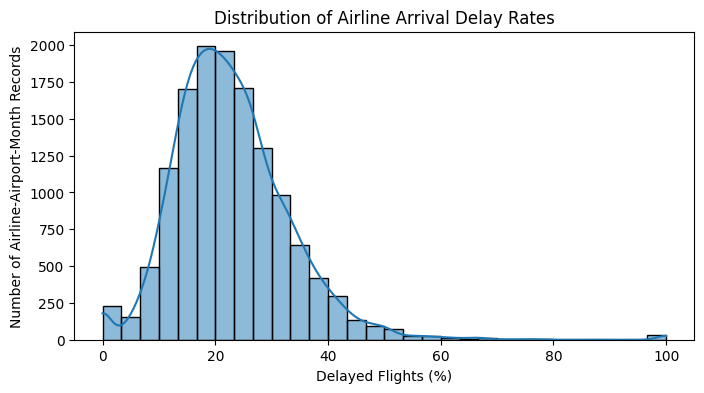

In [2]:

# Prepare the data for regression

reg_df = df[
    ["delay_rate", "airport", "carrier_name",
     "month", "year", "arr_flights"]
].copy()

# Remove rows missing any variables needed for the model
reg_df = reg_df.dropna()

# Keep rows with at least one arriving flight
reg_df = reg_df[reg_df["arr_flights"] > 0]

# Check our prepared data
print("Rows available for regression:", len(reg_df))
display(reg_df.head())

# Look at the distribution of delay rates
plt.figure(figsize=(8, 4))
sns.histplot(reg_df["delay_rate"] * 100, bins=30, kde=True)
plt.title("Distribution of Airline Arrival Delay Rates")
plt.xlabel("Delayed Flights (%)")
plt.ylabel("Number of Airline-Airport-Month Records")
plt.show()


### Initial Observations

After preparing the data, I have 13,472 observations available for regression. Looking at the histogram, most delay rates are concentrated between approximately 15% and 30%, with the highest frequency around 20%.

The distribution is slightly right-skewed, meaning there are some observations with much higher delay rates. A few records even have delay rates close to 100%. This suggests that although most airline-airport combinations have fairly similar delay rates, some experience much higher delays than others.

Next, I will use regression to examine whether differences in airports, airlines, months, and years help explain this variation.

In [3]:

import statsmodels.formula.api as smf

# Weighted regression model
model1 = smf.wls(
    formula="delay_rate ~ C(airport) + C(carrier_name) + C(month) + C(year)",
    data=reg_df,
    weights=reg_df["arr_flights"]
).fit(cov_type="HC3")

# Display regression results
print(model1.summary())

# Show model performance
print("\nR-squared:", round(model1.rsquared, 4))
print("Adjusted R-squared:", round(model1.rsquared_adj, 4))


                            WLS Regression Results                            
Dep. Variable:             delay_rate   R-squared:                       0.439
Model:                            WLS   Adj. R-squared:                  0.436
Method:                 Least Squares   F-statistic:                     110.9
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        07:57:34   Log-Likelihood:                 12085.
No. Observations:               13472   AIC:                        -2.406e+04
Df Residuals:                   13416   BIC:                        -2.364e+04
Df Model:                          55                                         
Covariance Type:                  HC3                                         
                                                                   coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------

### Regression Results and Interpretation

After running the weighted regression model, I got an R-squared value of 0.4386 and an adjusted R-squared of 0.4363. This means the airport, airline, month, and year together explain about 43.9% of the variation in delay rates in the weighted model.

One thing I noticed is that the month of the year seems to have an important relationship with delays. For example, July had a delay rate about 6.45 percentage points higher than January, while June was about 4.95 percentage points higher. October, on the other hand, had a lower delay rate than January by about 4.18 percentage points. These results were statistically significant.

I also noticed some differences between years. For example, 2025 had an estimated delay rate about 2.43 percentage points higher than 2022 after accounting for the other variables.

Overall, the regression results suggest that seasonal patterns are related to airline delays, especially during the summer months. However, the model does not explain all the variation in delay rates, so there are probably other factors that also affect delays. These findings show associations rather than proving that any particular factor causes delays.

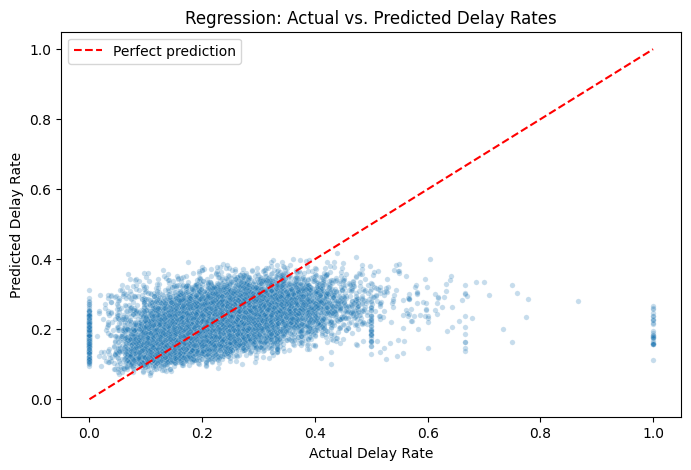

In [4]:

# Compare actual and predicted delay rates

reg_df["predicted_delay_rate"] = model1.predict(reg_df)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=reg_df,
    x="delay_rate",
    y="predicted_delay_rate",
    alpha=0.25,
    s=15
)

plt.plot([0, 1], [0, 1], "r--", label="Perfect prediction")

plt.xlabel("Actual Delay Rate")
plt.ylabel("Predicted Delay Rate")
plt.title("Regression: Actual vs. Predicted Delay Rates")
plt.legend()
plt.show()


### Actual vs. Predicted Delay Rates

I also compared the actual delay rates with the values predicted by my regression model. Looking at the graph, I noticed that most predictions are concentrated between 10% and 40%, even though some actual delay rates are much higher.

The model seems to capture general differences in delay rates, but it does not predict extreme values very well. For example, when the actual delay rate is close to 100%, the predicted rate is usually much lower.

This shows that airport, airline, month, and year provide useful information about delays, but they are not enough to explain every unusual situation. Other factors that are not included in this model may also be important.

## Model 2: K-means Clustering

For my second model, I will use K-means clustering to see which airports have similar delay patterns. Instead of looking at the overall delay rate, I want to compare the different reasons flights are delayed, such as weather, carrier-related issues, and late-arriving aircraft.

I chose clustering because it can help me group airports based on their similarities without deciding the groups in advance. This could help me understand whether certain airports tend to experience similar types of delays.

I will use the average distribution of delay causes for each airport and compare the resulting groups.

In [5]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select the five types of airline delays
delay_columns = [
    "carrier_ct",
    "weather_ct",
    "nas_ct",
    "security_ct",
    "late_aircraft_ct"
]

# Combine delay counts for each airport
airport_delays = df.groupby("airport")[delay_columns].sum()

# Calculate the total recorded delay causes
airport_delays["total_delay_causes"] = airport_delays[
    delay_columns
].sum(axis=1)

# Calculate the percentage for each delay cause
airport_patterns = airport_delays[delay_columns].div(
    airport_delays["total_delay_causes"], axis=0
) * 100

# Remove airports with no recorded delay causes
airport_patterns = airport_patterns.dropna()

# Display airport delay patterns
print("Number of airports:", len(airport_patterns))
display(airport_patterns.round(2))

# Standardize the data for K-means clustering
scaler = StandardScaler()
scaled_data = scaler.fit_transform(airport_patterns)

print("\nClustering data is ready!")


Number of airports: 20


,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct
airport,,,,,
ATL,31.84,3.84,25.47,0.19,38.66
BOS,28.78,2.61,34.84,0.20,33.58
CLT,26.46,4.72,24.87,0.27,43.68
DCA,24.73,3.05,36.16,0.21,35.85
DEN,31.75,3.59,31.10,0.17,33.39
DFW,28.09,6.32,26.12,0.29,39.18
DTW,39.62,6.62,20.22,0.23,33.32
EWR,23.24,3.11,48.82,0.14,24.68
IAH,31.97,3.70,33.13,0.13,31.07



Clustering data is ready!


,Number of Clusters,Silhouette Score
0,2,0.294
1,3,0.337
2,4,0.335
3,5,0.323
4,6,0.351
5,7,0.340
6,8,0.338


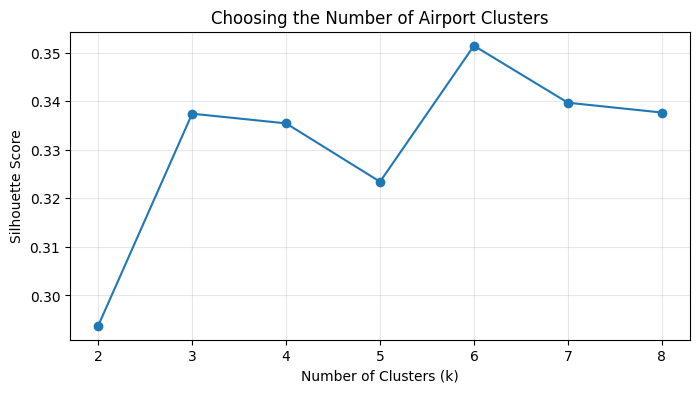

Best number of clusters: 6


In [6]:

# Test different numbers of clusters

k_values = range(2, 9)
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    cluster_labels = kmeans.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, cluster_labels)
    silhouette_scores.append(score)

# Display the silhouette scores
results = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Silhouette Score": silhouette_scores
})

display(results.round(3))

# Visualize the scores
plt.figure(figsize=(8, 4))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("Choosing the Number of Airport Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

# Identify the best k based on silhouette score
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Best number of clusters:", best_k)


In [7]:

# Fit K-means using the selected number of clusters
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

# Assign each airport to a cluster
airport_clusters = airport_patterns.copy()
airport_clusters["Cluster"] = (
    kmeans_final.fit_predict(scaled_data) + 1
)

# Display airports grouped by cluster
print("Airports in each cluster:")

for cluster in sorted(airport_clusters["Cluster"].unique()):
    airports = airport_clusters[
        airport_clusters["Cluster"] == cluster
    ].index.tolist()

    print(f"Cluster {cluster}: {', '.join(airports)}")

# Display average delay-cause percentages by cluster
cluster_summary = airport_clusters.groupby("Cluster").mean()

print("\nAverage delay-cause percentages by cluster:")
display(cluster_summary.round(2))

# Check cluster sizes
print("\nNumber of airports in each cluster:")
display(airport_clusters["Cluster"].value_counts().sort_index())


Airports in each cluster:
Cluster 1: LAX, MIA, SEA
Cluster 2: BOS, DCA, DEN, IAH, JFK, ORD
Cluster 3: DTW, MSP
Cluster 4: ATL, LAS, MCO, PHX
Cluster 5: CLT, DFW
Cluster 6: EWR, LGA, SFO

Average delay-cause percentages by cluster:


,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct
Cluster,,,,,
1,33.10,3.55,29.96,0.38,33.01
2,29.57,3.32,33.98,0.18,32.95
3,39.70,6.85,21.11,0.20,32.15
4,30.91,2.70,27.32,0.26,38.81
5,27.28,5.52,25.49,0.28,41.43
6,25.77,3.20,44.32,0.15,26.55



Number of airports in each cluster:


,count
Cluster,
1,3
2,6
3,2
4,4
5,2
6,3


### Clustering Results and Interpretation

After running K-means clustering, I got six groups of airports based on their delay patterns. Each cluster contained between two and six airports, which allowed me to compare the different groups.

One thing I noticed is that some airports have similar delay patterns even though they are located in different parts of the country. For example, DTW and MSP were grouped together in Cluster 3, where carrier-related delays made up about 39.70% of the recorded delay causes. This group also had the highest weather-related share at 6.85%.

Another interesting result was Cluster 6, which included EWR, LGA, and SFO. These airports had a much higher share of NAS-related delays, averaging 44.32%. Meanwhile, Cluster 5, which included CLT and DFW, had the highest late-aircraft delay share at 41.43%.

Overall, clustering helped me see that airports do not all experience the same types of delays. Some have more carrier-related delays, while others have larger shares of NAS or late-aircraft delays. However, the silhouette score of approximately 0.351 suggests the groups are only moderately separated, so I would not consider them completely distinct.

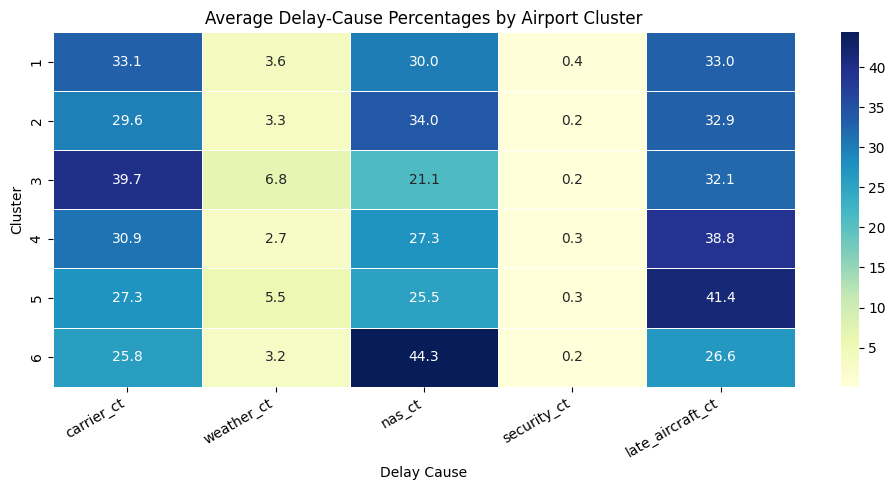

In [8]:

# Visualize average delay-cause percentages by cluster

plt.figure(figsize=(10, 5))

sns.heatmap(
    cluster_summary,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Delay-Cause Percentages by Airport Cluster")
plt.xlabel("Delay Cause")
plt.ylabel("Cluster")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### Clustering Visualization

The heatmap makes it easier to compare the six airport clusters. I noticed that Cluster 3 has the highest percentage of carrier-related delays, while Cluster 6 stands out because of its higher share of NAS-related delays.

Cluster 5 also has a higher percentage of late-aircraft delays compared with the other groups. Weather and security delays make up smaller shares across all six clusters.

Overall, the heatmap supports the clustering results by showing how the groups differ in their delay patterns. It also helped me understand why certain airports were grouped together.

## Model 3: Forecasting

For my third model, I will use forecasting to see whether past airline delay patterns can help predict future delays. In my previous data exploration, I noticed that delay rates seemed to change depending on the time of year, especially during the summer months.

I want to see whether these patterns appear consistently over time and whether they can be useful for estimating future delay rates.

For this analysis, I will first combine the data by month and calculate the overall percentage of delayed flights. Then I will build a forecasting model using the historical monthly data and evaluate how well it predicts more recent months.

Number of months: 55


,year,month,arr_flights,arr_del15,delay_rate
date,,,,,
2022-01-01,2022,1,292580,51125,17.473853
2022-02-01,2022,2,269379,49989,18.557126
2022-03-01,2022,3,303619,60996,20.089652
2022-04-01,2022,4,296888,60940,20.526259
2022-05-01,2022,5,310924,63459,20.409811


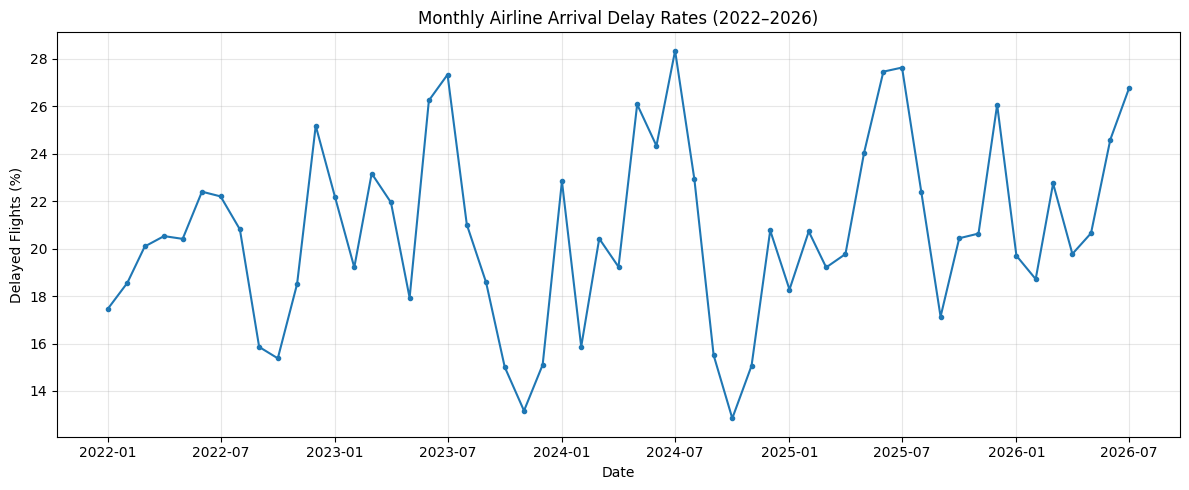

In [9]:

# Prepare monthly airline delay data for forecasting

# Combine total flights and delayed flights by year and month
monthly_data = df.groupby(
    ["year", "month"]
)[["arr_flights", "arr_del15"]].sum().reset_index()

# Create a date column
monthly_data["date"] = pd.to_datetime(
    monthly_data[["year", "month"]].assign(day=1)
)

# Calculate the overall monthly delay rate
monthly_data["delay_rate"] = (
    monthly_data["arr_del15"] /
    monthly_data["arr_flights"]
) * 100

# Sort chronologically
monthly_data = monthly_data.sort_values("date")

# Set date as the index
monthly_data = monthly_data.set_index("date")

# Display the first few observations
print("Number of months:", len(monthly_data))
display(monthly_data.head())

# Plot monthly delay rates
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data.index,
    monthly_data["delay_rate"],
    marker="o",
    markersize=3
)

plt.title("Monthly Airline Arrival Delay Rates (2022–2026)")
plt.xlabel("Date")
plt.ylabel("Delayed Flights (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Initial Time-Series Observations

After combining the data by month, I plotted the overall airline arrival delay rate from January 2022 through July 2026.

Looking at the graph, I noticed that delay rates change quite a bit throughout the year. There are several peaks during the summer months, especially around June and July, while some of the lowest rates occur during the fall.

However, the pattern is not exactly the same every year. This makes me interested in whether a forecasting model can capture some of these seasonal changes and predict future delay rates reasonably well.

In [10]:

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Set monthly frequency
ts = monthly_data["delay_rate"].asfreq("MS")

# Split into training and testing data
train = ts.loc[: "2025-12-01"]
test = ts.loc["2026-01-01":]

print("Training months:", len(train))
print("Testing months:", len(test))

# Build the Holt-Winters forecasting model
forecast_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

# Forecast the testing months
predictions = forecast_model.forecast(len(test))

# Evaluate the forecast
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))

print("\nForecasting Results")
print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual Delay Rate (%)": test,
    "Predicted Delay Rate (%)": predictions
})

display(comparison.round(2))


Training months: 48
Testing months: 7

Forecasting Results
Mean Absolute Error (MAE): 4.231
Root Mean Squared Error (RMSE): 4.351


,Actual Delay Rate (%),Predicted Delay Rate (%)
2026-01-01,19.70,24.34
2026-02-01,18.71,22.74
2026-03-01,22.74,24.87
2026-04-01,19.78,24.52
2026-05-01,20.65,26.27
2026-06-01,24.59,29.26
2026-07-01,26.75,30.53


### Forecasting Results and Interpretation

After running the Holt-Winters forecasting model, I got a Mean Absolute Error (MAE) of 4.231 and a Root Mean Squared Error (RMSE) of 4.351. This means my predictions were off by about 4.23 percentage points on average during the testing period.

When I compared the predicted values with the actual delay rates from January to July 2026, I noticed that the model predicted higher delay rates for every month. For example, in July, the model predicted 30.53%, while the actual delay rate was 26.75%.

Even though the predictions were not very close, the model still captured the general increase in delays toward the summer months. This suggests that historical seasonal patterns can provide some

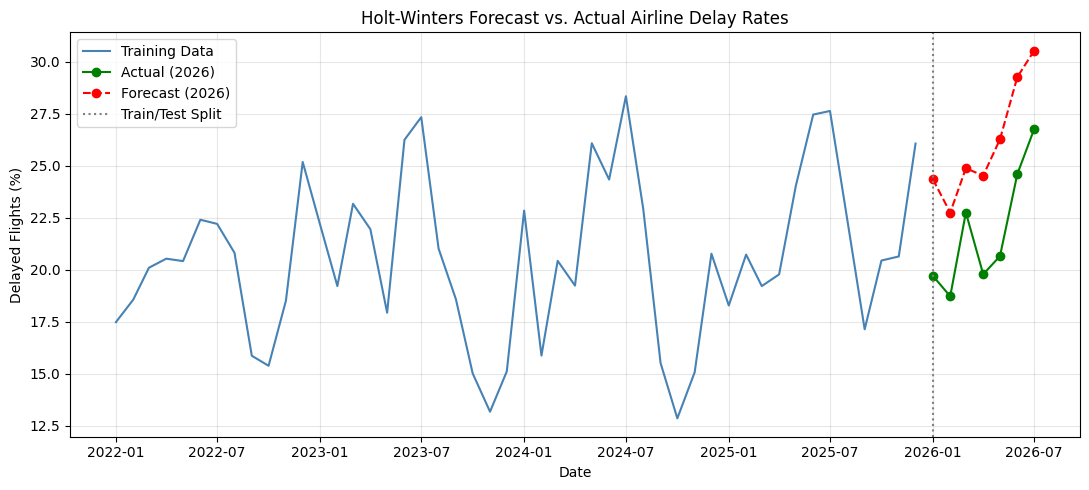

In [11]:

# Compare actual and forecasted delay rates

plt.figure(figsize=(11, 5))

# Historical training data
plt.plot(
    train.index,
    train,
    label="Training Data",
    color="steelblue"
)

# Actual testing data
plt.plot(
    test.index,
    test,
    label="Actual (2026)",
    marker="o",
    color="green"
)

# Forecasted testing data
plt.plot(
    predictions.index,
    predictions,
    label="Forecast (2026)",
    marker="o",
    linestyle="--",
    color="red"
)

plt.axvline(
    pd.Timestamp("2026-01-01"),
    color="gray",
    linestyle=":",
    label="Train/Test Split"
)

plt.title("Holt-Winters Forecast vs. Actual Airline Delay Rates")
plt.xlabel("Date")
plt.ylabel("Delayed Flights (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Forecasting Visualization

Looking at the graph, I can see that the model follows some of the seasonal patterns from previous years. Both the predicted and actual delay rates increase toward the summer months in 2026.

However, the predicted values are higher than the actual values throughout the testing period. This shows that the model was able to capture the general direction of the delays, but it was less accurate when estimating the actual percentages.

I think forecasting is useful for understanding seasonal trends, but this model would need improvement before I could rely on it for more accurate predictions.

## Overall Conclusion

In this assignment, I used three different modeling methods to better understand airline delays across 20 major U.S. airports.

For the first model, I used weighted regression to examine how airports, airlines, months, and years are related to arrival delay rates. The model explained about 43.9% of the weighted variation in delay rates. One of the main things I noticed was that delays tended to be higher during the summer months, especially June and July.

For the second model, I used K-means clustering to group airports with similar delay patterns. I found six clusters, and some groups stood out because they had higher shares of carrier-related, NAS-related, or late-aircraft delays. This helped me understand that different airports can experience different types of delays.

For the third model, I used Holt-Winters forecasting to estimate monthly airline delays using historical data. The model had a mean absolute error of 4.231 percentage points, and its predictions were consistently higher than the actual delay rates in 2026. However, it still captured the general increase in delays toward the summer.

Overall, these three models helped me look at airline delays from different perspectives. Regression helped me understand relationships between variables, clustering helped me identify similarities between airports, and forecasting helped me evaluate how useful historical patterns are for predicting future delays. I also learned that even when models find useful patterns, they still have limitations and cannot explain every situation.